<a href="https://colab.research.google.com/github/vanitripathi24/UCS420/blob/main/ucs420_assgn10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
##assgn 10


In [2]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn

In [3]:
import nltk
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries imported successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully!


In [4]:
data = {

    "glucose_monitoring": [
        "How can I check my blood sugar?",
        "What is a normal fasting glucose level?",
        "When should I test my glucose?",
        "How often should diabetics monitor sugar?",
        "What is HbA1c?",
        "How does a glucometer work?",
        "Why is my blood sugar high in the morning?",
        "What should I do before a glucose test?"
    ],

    "diabetes_symptoms": [
        "What are the symptoms of diabetes?",
        "Why am I feeling thirsty all the time?",
        "Does frequent urination indicate diabetes?",
        "Why do diabetic patients feel tired?",
        "Can diabetes cause blurred vision?",
        "What causes unexplained weight loss?",
        "Why do I feel hungry frequently?",
        "Can diabetes cause slow wound healing?"
    ],

    "diabetes_diet": [
        "What foods should diabetics eat?",
        "Can diabetic patients eat rice?",
        "Which fruits are good for diabetes?",
        "Should diabetics avoid sugar?",
        "What is a healthy breakfast for diabetes?",
        "Can I drink fruit juice with diabetes?",
        "What foods help control blood sugar?",
        "Is whole wheat bread good for diabetics?"
    ],

    "diabetes_exercise": [
        "What exercises are good for diabetics?",
        "Can walking help control diabetes?",
        "How long should a diabetic walk daily?",
        "Is yoga beneficial for diabetes?",
        "Can exercise lower blood glucose?",
        "When should diabetics exercise?",
        "Is cycling good for diabetic patients?",
        "What precautions should I take while exercising?"
    ],

    "medication_info": [
        "What is metformin used for?",
        "Why do diabetic patients take insulin?",
        "What are common side effects of metformin?",
        "How should insulin be stored?",
        "What are the different types of insulin?",
        "Can diabetes medicine cause low sugar?",
        "Why is medication important for diabetes?",
        "What should I ask my doctor about insulin?"
    ],

    "complications": [
        "Can diabetes damage the kidneys?",
        "How does diabetes affect eyesight?",
        "Can diabetes cause nerve damage?",
        "What is diabetic neuropathy?",
        "Can diabetes cause heart disease?",
        "Why do diabetic wounds heal slowly?",
        "What are long term effects of diabetes?",
        "How does diabetes affect the feet?"
    ],

    "prevention": [
        "How can I prevent type 2 diabetes?",
        "Can healthy eating reduce diabetes risk?",
        "Does weight management help prevent diabetes?",
        "How can I reduce my risk of diabetes?",
        "Is regular exercise important for prevention?",
        "Can lifestyle changes prevent diabetes?",
        "Why is maintaining healthy weight important?",
        "How often should I get screened for diabetes?"
    ]
}

# Convert dictionary into a DataFrame

records = []

for intent, queries in data.items():
    for query in queries:
        records.append({
            "query": query,
            "intent": intent
        })

df = pd.DataFrame(records)

print("Total queries:", len(df))
print("\nIntent distribution:")
print(df["intent"].value_counts())

df.head(10)

Total queries: 56

Intent distribution:
intent
glucose_monitoring    8
diabetes_symptoms     8
diabetes_diet         8
diabetes_exercise     8
medication_info       8
complications         8
prevention            8
Name: count, dtype: int64


,query,intent
0,How can I check my blood sugar?,glucose_monitoring
1,What is a normal fasting glucose level?,glucose_monitoring
2,When should I test my glucose?,glucose_monitoring
3,How often should diabetics monitor sugar?,glucose_monitoring
4,What is HbA1c?,glucose_monitoring
5,How does a glucometer work?,glucose_monitoring
6,Why is my blood sugar high in the morning?,glucose_monitoring
7,What should I do before a glucose test?,glucose_monitoring
8,What are the symptoms of diabetes?,diabetes_symptoms
9,Why am I feeling thirsty all the time?,diabetes_symptoms


In [5]:
taxonomy = {

    "Diabetes Monitoring": [
        "Glucose Testing",
        "Blood Sugar Interpretation"
    ],

    "Diabetes Management": [
        "Diet and Nutrition",
        "Exercise and Lifestyle"
    ],

    "Medical Information": [
        "Medication Information",
        "Symptoms and Complications"
    ],

    "Diabetes Prevention and Safety": [
        "Risk Reduction",
        "Emergency Warning Signs"
    ]
}

print("DIABETES HEALTHCARE TAXONOMY\n")

for category, subcategories in taxonomy.items():

    print(category)

    for subcategory in subcategories:
        print("   └──", subcategory)

DIABETES HEALTHCARE TAXONOMY

Diabetes Monitoring
   └── Glucose Testing
   └── Blood Sugar Interpretation
Diabetes Management
   └── Diet and Nutrition
   └── Exercise and Lifestyle
Medical Information
   └── Medication Information
   └── Symptoms and Complications
Diabetes Prevention and Safety
   └── Risk Reduction
   └── Emergency Warning Signs


In [6]:
concepts = [
    "Diabetes",
    "Blood Glucose",
    "Insulin",
    "Pancreas",
    "HbA1c",
    "Metformin",
    "Diet",
    "Exercise",
    "Kidneys",
    "Neuropathy",
    "Glucometer",
    "Hypoglycemia"
]

relationships = [
    ("Diabetes", "affects", "Blood Glucose"),
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "helps regulate", "Blood Glucose"),
    ("HbA1c", "measures", "Average Blood Glucose"),
    ("Metformin", "is used for", "Type 2 Diabetes"),
    ("Diet", "influences", "Blood Glucose"),
    ("Exercise", "helps regulate", "Blood Glucose"),
    ("Diabetes", "can damage", "Kidneys"),
    ("Diabetes", "can cause", "Neuropathy"),
    ("Glucometer", "measures", "Blood Glucose"),
    ("Insulin", "can cause", "Hypoglycemia"),
    ("Diet and Exercise", "support management of", "Diabetes")
]

print("DOMAIN CONCEPTS:")
for concept in concepts:
    print("-", concept)

print("\nDOMAIN RELATIONSHIPS:")
for subject, relation, obj in relationships:
    print(subject, "--", relation, "-->", obj)

DOMAIN CONCEPTS:
- Diabetes
- Blood Glucose
- Insulin
- Pancreas
- HbA1c
- Metformin
- Diet
- Exercise
- Kidneys
- Neuropathy
- Glucometer
- Hypoglycemia

DOMAIN RELATIONSHIPS:
Diabetes -- affects --> Blood Glucose
Pancreas -- produces --> Insulin
Insulin -- helps regulate --> Blood Glucose
HbA1c -- measures --> Average Blood Glucose
Metformin -- is used for --> Type 2 Diabetes
Diet -- influences --> Blood Glucose
Exercise -- helps regulate --> Blood Glucose
Diabetes -- can damage --> Kidneys
Diabetes -- can cause --> Neuropathy
Glucometer -- measures --> Blood Glucose
Insulin -- can cause --> Hypoglycemia
Diet and Exercise -- support management of --> Diabetes


In [7]:
stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words = stop_words - {"not", "no", "never"}

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Tokenization
    tokens = word_tokenize(text)

    # Remove punctuation and numbers
    tokens = [
        word for word in tokens
        if word.isalpha()
    ]

    # 3. Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 4. Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


df["processed_query"] = df["query"].apply(preprocess_text)

print("Original and Processed Queries:\n")

display(df[["query", "processed_query", "intent"]].head(10))

Original and Processed Queries:



,query,processed_query,intent
0,How can I check my blood sugar?,check blood sugar,glucose_monitoring
1,What is a normal fasting glucose level?,normal fasting glucose level,glucose_monitoring
2,When should I test my glucose?,test glucose,glucose_monitoring
3,How often should diabetics monitor sugar?,often diabetic monitor sugar,glucose_monitoring
4,What is HbA1c?,,glucose_monitoring
5,How does a glucometer work?,glucometer work,glucose_monitoring
6,Why is my blood sugar high in the morning?,blood sugar high morning,glucose_monitoring
7,What should I do before a glucose test?,glucose test,glucose_monitoring
8,What are the symptoms of diabetes?,symptom diabetes,diabetes_symptoms
9,Why am I feeling thirsty all the time?,feeling thirsty time,diabetes_symptoms


In [8]:
X = df["processed_query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 42
Testing samples: 14


In [9]:
# TF-IDF vectorization

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

# Train Logistic Regression classifier

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("\nModel training completed successfully!")

Training feature shape: (42, 181)
Testing feature shape: (14, 181)

Model training completed successfully!


In [10]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

MODEL EVALUATION RESULTS
----------------------------------------
Accuracy : 0.2143
Precision: 0.2
Recall   : 0.2143
F1 Score : 0.1769

Classification Report:

                    precision    recall  f1-score   support

     complications       0.00      0.00      0.00         2
     diabetes_diet       0.00      0.00      0.00         2
 diabetes_exercise       0.20      0.50      0.29         2
 diabetes_symptoms       0.00      0.00      0.00         2
glucose_monitoring       0.00      0.00      0.00         2
   medication_info       0.20      0.50      0.29         2
        prevention       1.00      0.50      0.67         2

          accuracy                           0.21        14
         macro avg       0.20      0.21      0.18        14
      weighted avg       0.20      0.21      0.18        14



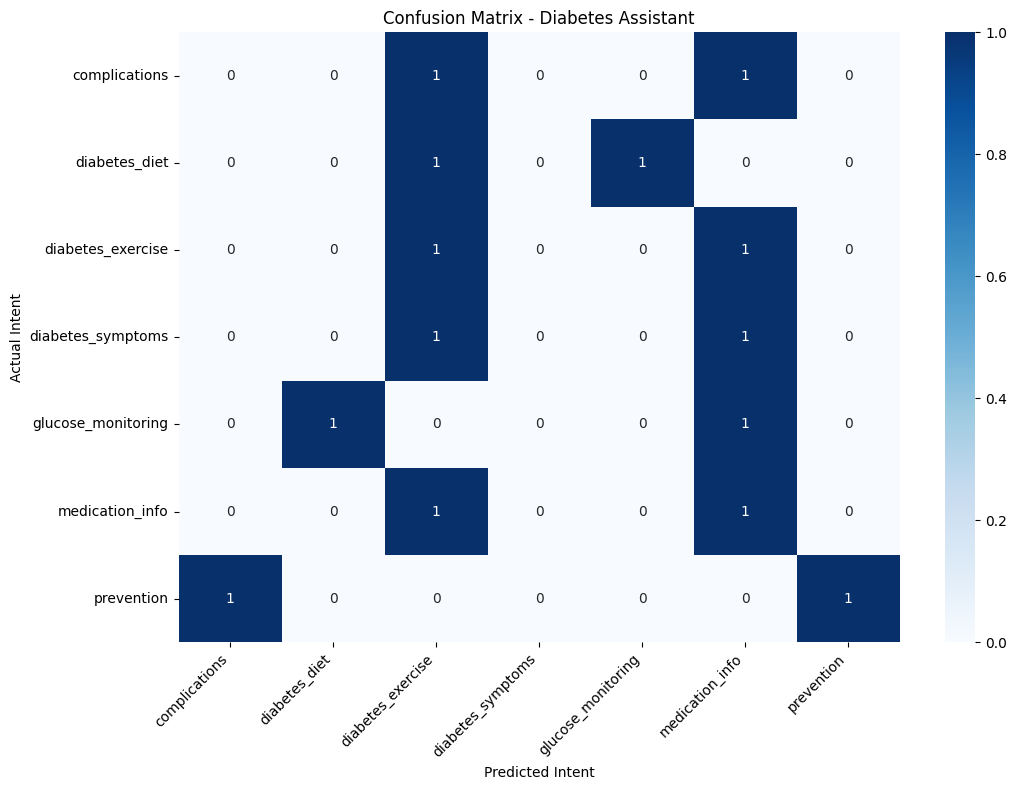

In [11]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")
plt.title("Confusion Matrix - Diabetes Assistant")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [12]:
knowledge_base = {

    "glucose_monitoring": """
    Blood glucose monitoring helps people understand
    their blood sugar levels.

    Common tests include fasting blood glucose,
    post-meal glucose and HbA1c.

    A glucometer can be used for home glucose monitoring.
    Follow your healthcare provider's testing schedule.
    """,

    "diabetes_symptoms": """
    Common symptoms of diabetes include frequent urination,
    excessive thirst, increased hunger, fatigue,
    blurred vision and unexplained weight changes.

    Symptoms alone cannot confirm diabetes.
    Consult a healthcare professional for testing.
    """,

    "diabetes_diet": """
    A balanced diabetes-friendly diet can include
    whole grains, vegetables, legumes, fruits in
    appropriate portions and healthy protein sources.

    Limit sugary drinks and highly processed foods.
    Individual meal plans should be discussed with
    a registered dietitian or healthcare provider.
    """,

    "diabetes_exercise": """
    Regular physical activity can improve insulin
    sensitivity and support blood glucose management.

    Walking, cycling, swimming and yoga may be helpful.

    Adults are generally encouraged to aim for at least
    150 minutes of moderate activity per week, if
    medically appropriate.
    """,

    "medication_info": """
    Metformin is commonly used to manage type 2 diabetes.

    Insulin is a hormone that helps glucose enter cells.
    Some people with diabetes require insulin therapy.

    Medicines should only be taken as prescribed.
    Never change medication dosage without consulting
    a healthcare professional.
    """,

    "complications": """
    Diabetes can increase the risk of complications
    affecting the eyes, kidneys, nerves, heart and feet.

    Regular medical checkups, blood glucose management
    and preventive care can help reduce risks.
    """,

    "prevention": """
    Type 2 diabetes risk may be reduced through
    healthy eating, regular exercise, maintaining
    a healthy weight and avoiding tobacco.

    Regular health screening can help identify
    elevated blood glucose early.
    """
}

print("Diabetes Knowledge Base Created!")

for intent in knowledge_base:
    print("-", intent)

Diabetes Knowledge Base Created!
- glucose_monitoring
- diabetes_symptoms
- diabetes_diet
- diabetes_exercise
- medication_info
- complications
- prevention


In [13]:
# Emergency keywords
emergency_keywords = [
    "unconscious",
    "unresponsive",
    "seizure",
    "convulsion",
    "cannot breathe",
    "difficulty breathing",
    "chest pain",
    "fainting",
    "passed out",
    "severe confusion",
    "not waking",
    "vomiting blood"
]

# Diabetes domain keywords
domain_keywords = [
    "diabetes", "diabetic", "glucose", "blood sugar",
    "sugar level", "insulin", "metformin", "hba1c",
    "glucometer", "hypoglycemia", "hyperglycemia",
    "kidney", "neuropathy", "diabetic diet",
    "diabetic foot", "fasting sugar", "diabetes risk",
    "low sugar", "high sugar"
]

def is_emergency(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in emergency_keywords
    )


def is_diabetes_related(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in domain_keywords
    )


def diabetes_assistant(query):

    # RULE 1: Emergency escalation
    if is_emergency(query):

        return """
        🚨 EMERGENCY ALERT

        This may indicate a medical emergency.

        Call India's emergency number 112 or your
        local emergency service immediately.

        Do not delay professional medical care.
        Do not give food or drink to an unconscious person.

        Seek immediate medical attention.
        """

    # RULE 2: Unsupported query handling
    if not is_diabetes_related(query):

        return """
        I am a Diabetes Care Information Assistant.

        Your query appears to be outside my supported
        diabetes-care knowledge domain.

        Please ask me about blood glucose, symptoms,
        diet, exercise, medication, complications
        or diabetes prevention.
        """

    # NLP preprocessing
    processed = preprocess_text(query)

    # TF-IDF transformation
    vector = tfidf.transform([processed])

    # Intent prediction
    probabilities = model.predict_proba(vector)[0]

    predicted_index = np.argmax(probabilities)

    intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    # RULE 3: Low-confidence handling
    if confidence < 0.40:

        return f"""
        I am not sufficiently confident about understanding
        your query.

        Confidence: {confidence:.2f}

        Please rephrase your question using more specific
        diabetes-related terms or consult a healthcare
        professional.
        """

    # RULE 4: Knowledge retrieval
    response = knowledge_base[intent]

    # RULE 5: Safety disclaimer
    final_response = f"""
    🩺 DIABETES CARE INFORMATION ASSISTANT

    Detected Intent: {intent}

    Confidence Score: {confidence:.2f}

    INFORMATION:

    {response}

    DISCLAIMER:
    This assistant provides general educational
    information and does not replace professional
    medical diagnosis or treatment.

    Consult your doctor for personal medical advice.
    """

    return final_response


print("All five reasoning rules implemented!")

All five reasoning rules implemented!


In [14]:
test_cases = [

    # 1. Query belonging to a defined intent
    "What foods should diabetics eat?",

    # 2. Differently worded query
    "My sugar shoots up after eating meals.",

    # 3. Unsupported healthcare query
    "What are the symptoms of malaria?",

    # 4. Low-confidence / ambiguous query
    "Diabetes sugar maybe something is happening.",

    # 5. Emergency-related query
    "A diabetic person is unconscious and not waking up."

]

for i, query in enumerate(test_cases, 1):

    print("\n" + "=" * 65)
    print(f"TEST CASE {i}")
    print("=" * 65)

    print("User Query:", query)

    print("\nAssistant Response:")
    print(diabetes_assistant(query))


TEST CASE 1
User Query: What foods should diabetics eat?

Assistant Response:

        I am not sufficiently confident about understanding
        your query.

        Confidence: 0.29

        Please rephrase your question using more specific
        diabetes-related terms or consult a healthcare
        professional.
        

TEST CASE 2
User Query: My sugar shoots up after eating meals.

Assistant Response:

        I am a Diabetes Care Information Assistant.

        Your query appears to be outside my supported
        diabetes-care knowledge domain.

        Please ask me about blood glucose, symptoms,
        diet, exercise, medication, complications
        or diabetes prevention.
        

TEST CASE 3
User Query: What are the symptoms of malaria?

Assistant Response:

        I am a Diabetes Care Information Assistant.

        Your query appears to be outside my supported
        diabetes-care knowledge domain.

        Please ask me about blood glucose, symptoms,
        d

In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Input box
query_box = widgets.Textarea(
    placeholder="Ask a question about diabetes care...",
    description="Query:",
    layout=widgets.Layout(width="90%", height="80px")
)

# Button
submit_button = widgets.Button(
    description="Ask Assistant",
    button_style="success",
    icon="comment"
)

# Output area
output_area = widgets.Output()

def respond_to_query(button):

    with output_area:

        clear_output()

        query = query_box.value.strip()

        if not query:
            print("Please enter a question.")
            return

        print("USER:", query)
        print("\nASSISTANT:")
        print(diabetes_assistant(query))

submit_button.on_click(respond_to_query)

display(query_box, submit_button, output_area)

Textarea(value='', description='Query:', layout=Layout(height='80px', width='90%'), placeholder='Ask a questio…

Button(button_style='success', description='Ask Assistant', icon='comment', style=ButtonStyle())

Output()

In [16]:
sample_queries = [
    "How can I monitor my glucose levels?",
    "Can walking improve blood sugar?",
    "What is metformin?",
    "Can diabetes affect kidneys?",
    "How can I prevent type 2 diabetes?"
]

for query in sample_queries:

    print("\nUSER:", query)
    print("-" * 50)

    print(diabetes_assistant(query))


USER: How can I monitor my glucose levels?
--------------------------------------------------

        I am not sufficiently confident about understanding
        your query.

        Confidence: 0.28

        Please rephrase your question using more specific
        diabetes-related terms or consult a healthcare
        professional.
        

USER: Can walking improve blood sugar?
--------------------------------------------------

        I am not sufficiently confident about understanding
        your query.

        Confidence: 0.26

        Please rephrase your question using more specific
        diabetes-related terms or consult a healthcare
        professional.
        

USER: What is metformin?
--------------------------------------------------

        I am not sufficiently confident about understanding
        your query.

        Confidence: 0.26

        Please rephrase your question using more specific
        diabetes-related terms or consult a healthcare
        prof

In [17]:
# Demonstrate low-confidence handling

original_threshold = 0.40

# Temporarily increase threshold for demonstration
demo_threshold = 0.99

query = "Diabetes sugar maybe something is happening."

processed = preprocess_text(query)
vector = tfidf.transform([processed])

confidence = max(model.predict_proba(vector)[0])

print("Query:", query)
print("Actual model confidence:", round(confidence, 3))

if confidence < demo_threshold:
    print("\nLOW CONFIDENCE RULE ACTIVATED")
    print("Please rephrase your query.")

else:
    print("Model confidence is high.")

Query: Diabetes sugar maybe something is happening.
Actual model confidence: 0.167

LOW CONFIDENCE RULE ACTIVATED
Please rephrase your query.
